# Rabtech Academy — Task 4: Exploratory Data Analysis & Statistical Insights

## Objective
Explore the cleaned Global Superstore dataset using descriptive statistics, distributions, correlation analysis, multivariate visualizations, and three business hypothesis tests.

**Dataset:** `data/clean_dataset.csv`  
**Rows:** 51,290 transaction-line records  
**Important grain note:** A row represents a product line, not necessarily a unique order. Repeated Order IDs are expected.

## Questions
1. What do sales, profit, discount, shipping cost, quantity, and profit margin distributions look like?
2. Which numerical variables move together?
3. Are discount levels associated with profit margin?
4. Do average sales differ across customer segments?
5. Does average profit differ across product categories?


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme()  # use default seaborn theme for readable charts
DATA_PATH = Path("/clean_dataset.csv")
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

# Parse date and ensure numeric fields are numeric
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
numeric_cols = ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost", "Profit Margin (%)"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Shape:", df.shape)
print("Unique orders:", df["Order ID"].nunique())
display(df.head())


Dataset loaded successfully!
Shape: (51290, 31)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Profit,Shipping Cost,Order Priority,Sales Outlier Flag,Profit Outlier Flag,Shipping Cost Outlier Flag,Order Year,Order Month,Order Month Name,Profit Margin (%)
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,92.025,57.21,Critical,True,True,True,2012,7,July,15.825586
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,-55.215,57.21,Critical,True,True,True,2013,2,February,-9.495351
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,92.025,57.21,Medium,True,True,True,2013,10,October,15.825586
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,-55.215,57.21,Medium,True,True,True,2013,1,January,-9.495351
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,92.025,57.21,Critical,True,True,True,2013,11,November,15.825586


Shape: (51290, 31)
Unique orders: 25035


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Profit,Shipping Cost,Order Priority,Sales Outlier Flag,Profit Outlier Flag,Shipping Cost Outlier Flag,Order Year,Order Month,Order Month Name,Profit Margin (%)
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,92.025,57.21,Critical,True,True,True,2012,7,July,15.825586
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,-55.215,57.21,Critical,True,True,True,2013,2,February,-9.495351
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,92.025,57.21,Medium,True,True,True,2013,10,October,15.825586
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,-55.215,57.21,Medium,True,True,True,2013,1,January,-9.495351
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,92.025,57.21,Critical,True,True,True,2013,11,November,15.825586


In [20]:
import os

print(os.getcwd())
print(os.listdir('/'))

/content
['sys', 'mnt', 'lib64', 'run', 'home', 'var', 'tmp', 'usr', 'srv', 'dev', 'sbin', 'root', 'proc', 'opt', 'etc', 'lib', 'boot', 'media', 'bin', 'clean_dataset.csv', 'kaggle', '.dockerenv', 'backend-container', 'datalab', 'tools', 'content', 'python-apt', 'python-apt.tar.xz', 'sbin.usr-is-merged', 'bin.usr-is-merged', 'lib.usr-is-merged']


## 1. Descriptive statistics

The table reports count, mean, standard deviation, minimum, quartiles, median (50%), and maximum. Compare mean and median to identify skew.

In [12]:
descriptive = df[numeric_cols].describe().T
descriptive["median"] = df[numeric_cols].median()
display(descriptive.round(2))


,count,mean,std,min,25%,50%,75%,max,median
Sales,51290.0,172.36,190.10,0.44,30.76,85.05,251.05,581.50,85.05
Quantity,51290.0,3.48,2.28,1.00,2.00,3.00,5.00,14.00,3.00
Discount,51290.0,0.14,0.21,0.00,0.00,0.00,0.20,0.85,0.00
Profit,51290.0,18.09,39.85,-55.22,0.00,9.24,36.81,92.02,9.24
Shipping Cost,51290.0,16.71,18.98,0.00,2.61,7.79,24.45,57.21,7.79
Profit Margin (%),51290.0,6.34,39.69,-275.00,0.00,15.83,29.98,50.00,15.83


## 2. Distribution analysis — histograms

Histograms show the shape and spread of each numeric measure. Long right tails indicate that a small number of transactions have relatively large values.

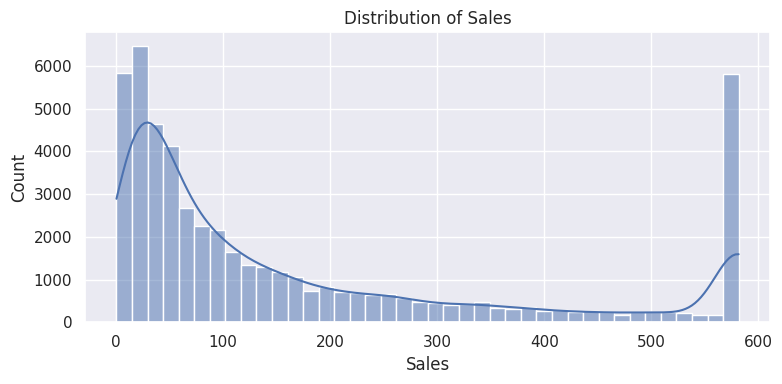

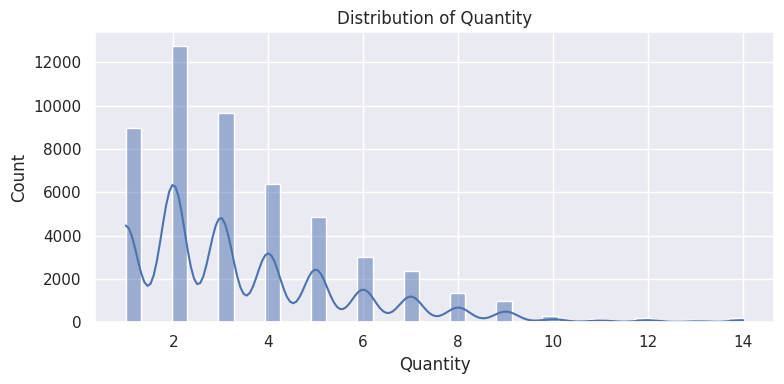

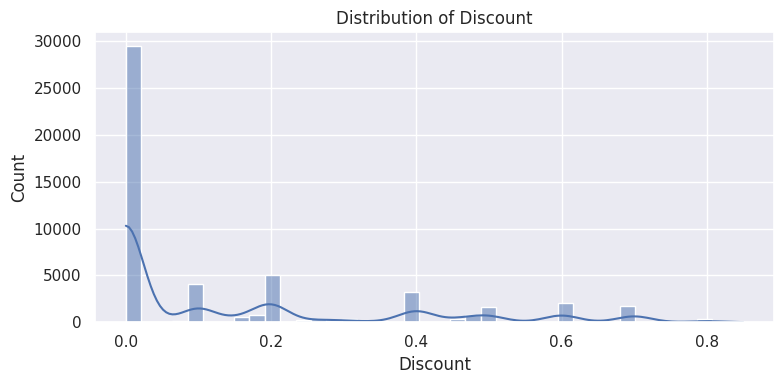

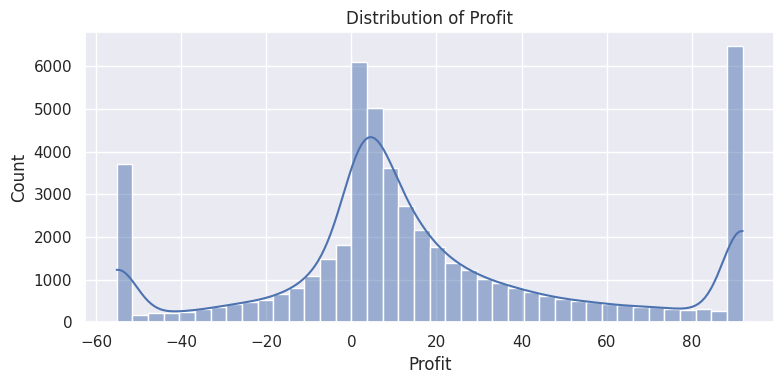

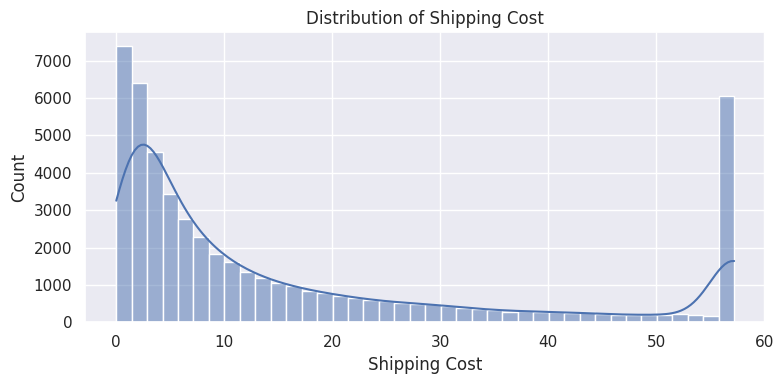

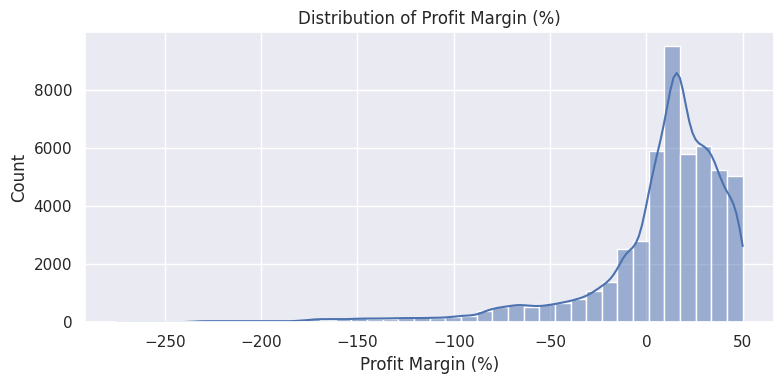

In [13]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, bins=40, kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()


## 3. Outlier inspection — box plots

Box plots use the 1.5×IQR rule to flag potential outliers. A flagged value is not automatically an error; business context is needed before excluding it.

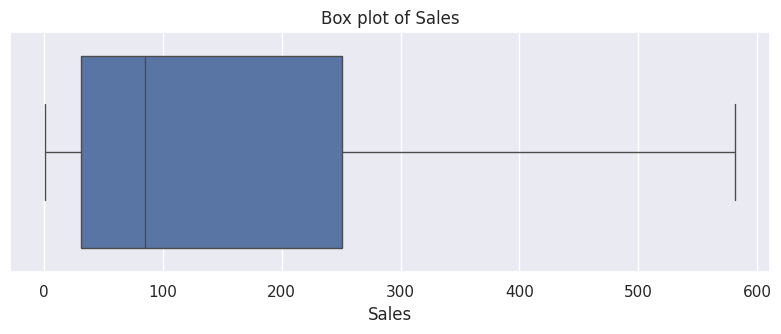

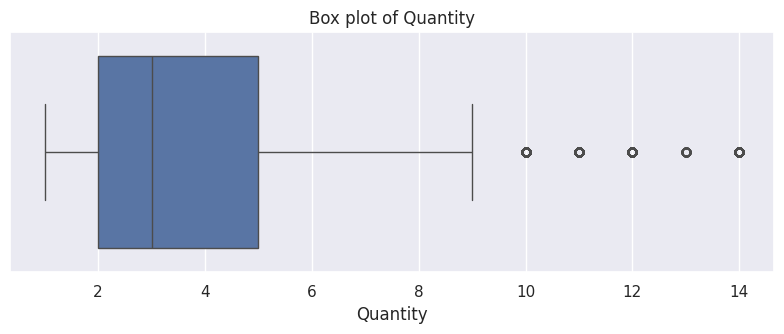

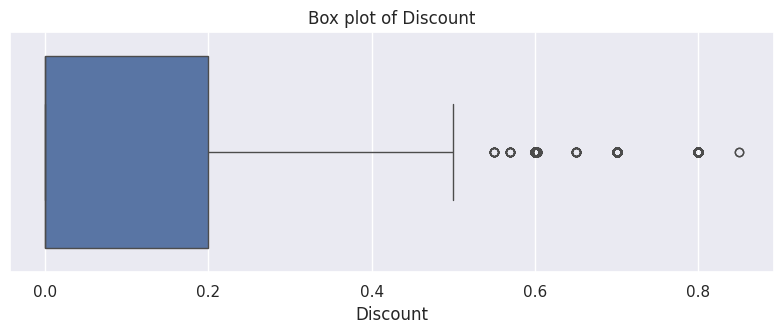

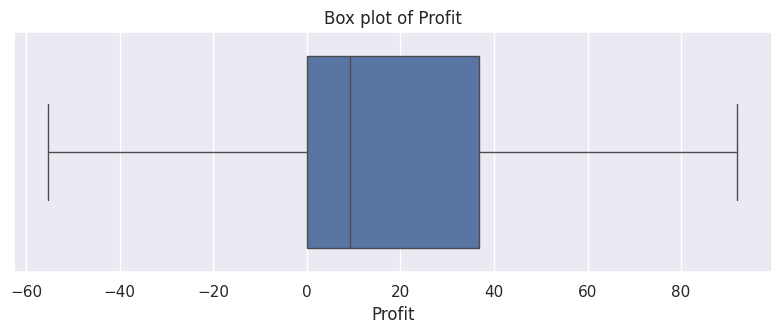

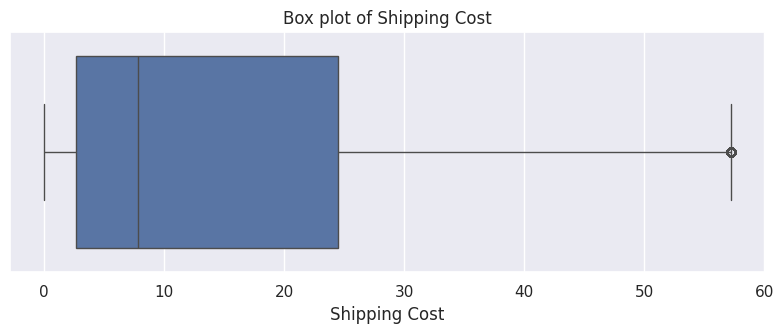

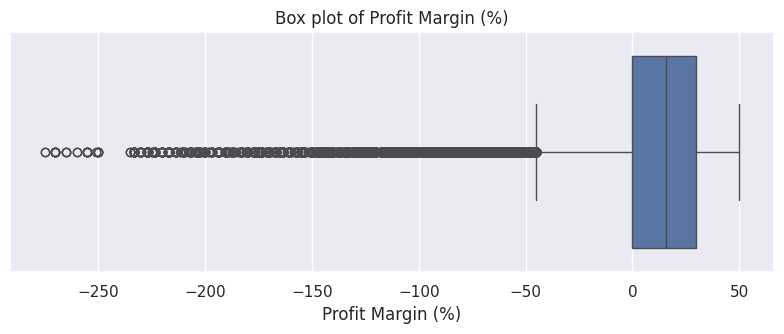

,Variable,IQR lower bound,IQR upper bound,Potential outliers,Percent
0,Sales,-299.68,581.50,0,0.00
1,Quantity,-2.50,9.50,877,1.71
2,Discount,-0.30,0.50,4172,8.13
3,Profit,-55.22,92.02,0,0.00
4,Shipping Cost,-30.15,57.21,5909,11.52
5,Profit Margin (%),-44.97,74.95,4677,9.12


In [14]:
for col in numeric_cols:
    plt.figure(figsize=(8, 3.5))
    sns.boxplot(data=df, x=col)
    plt.title(f"Box plot of {col}")
    plt.tight_layout()
    plt.show()

outlier_summary = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, lower, upper, int(count), round(count / len(df) * 100, 2)])
outlier_summary = pd.DataFrame(outlier_summary, columns=["Variable", "IQR lower bound", "IQR upper bound", "Potential outliers", "Percent"])
display(outlier_summary.round(2))


## 4. Correlation matrix and heatmap

Pearson correlation measures linear association between numeric variables. Correlation does not establish causation.

,Sales,Quantity,Discount,Profit,Shipping Cost,Profit Margin (%)
Sales,1.000,0.352,-0.128,0.483,0.890,0.095
Quantity,0.352,1.000,-0.020,0.179,0.324,0.064
Discount,-0.128,-0.020,1.000,-0.567,-0.121,-0.813
Profit,0.483,0.179,-0.567,1.000,0.442,0.498
Shipping Cost,0.890,0.324,-0.121,0.442,1.000,0.095
Profit Margin (%),0.095,0.064,-0.813,0.498,0.095,1.000


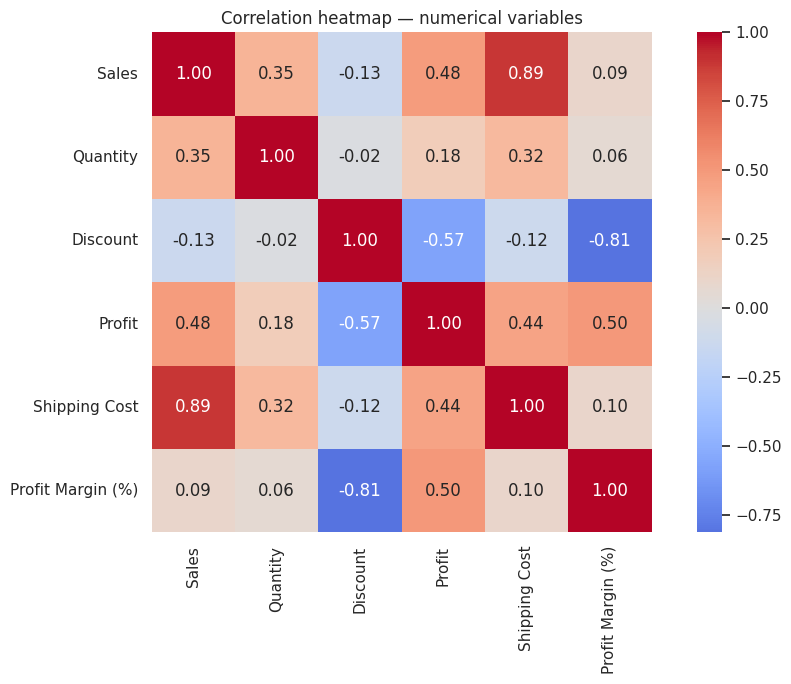

In [15]:
corr = df[numeric_cols].corr(method="pearson")
display(corr.round(3))
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap — numerical variables")
plt.tight_layout()
plt.show()


## 5. Multivariate business views

These plots compare multiple dimensions at once to reveal patterns across product category, customer segment, discount, sales, and profit.

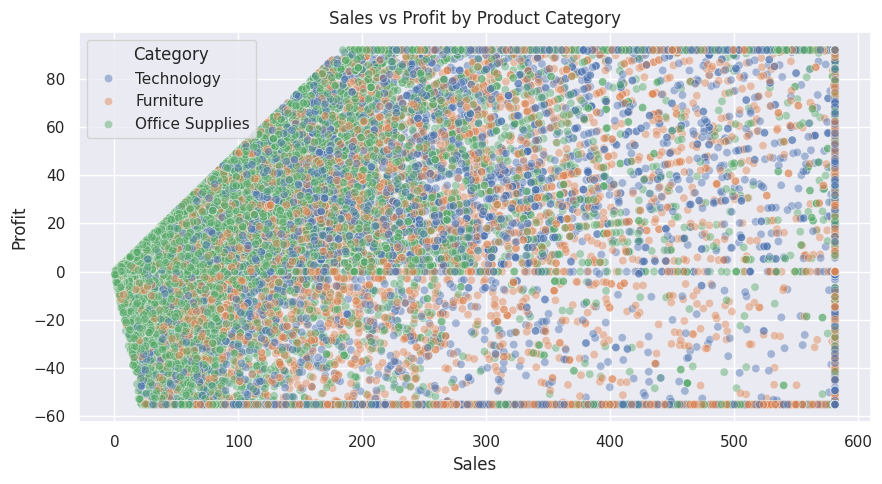

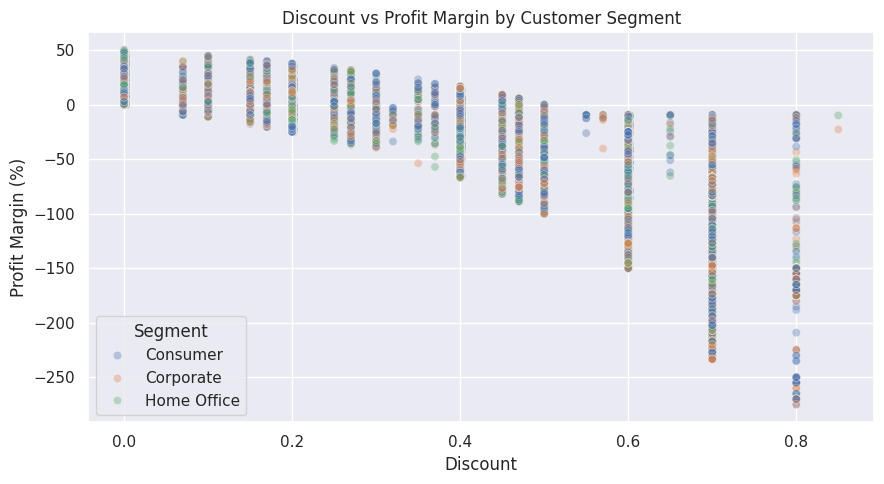

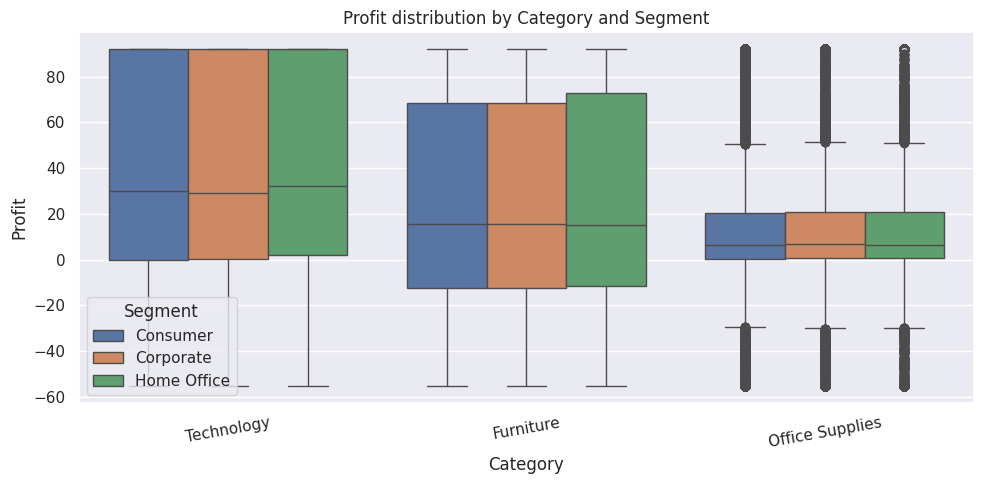

In [16]:
# Sales and profit by category
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Sales", y="Profit", hue="Category", alpha=0.45)
plt.title("Sales vs Profit by Product Category")
plt.tight_layout()
plt.show()

# Discount and profit margin
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Discount", y="Profit Margin (%)", hue="Segment", alpha=0.35)
plt.title("Discount vs Profit Margin by Customer Segment")
plt.tight_layout()
plt.show()

# Category and segment comparison
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Category", y="Profit", hue="Segment")
plt.title("Profit distribution by Category and Segment")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


## 6. Business hypotheses and statistical tests

Use a 5% significance level (α = 0.05). The tests evaluate association/differences, not causality.

### Hypothesis 1 — Discount and profit margin
- **H₀:** Discount rate and profit margin have no monotonic association.
- **H₁:** Discount rate and profit margin have a monotonic association.
- **Test:** Spearman rank correlation (robust to non-normal distributions).

### Hypothesis 2 — Sales across customer segments
- **H₀:** Mean sales are equal across Consumer, Corporate, and Home Office segments.
- **H₁:** At least one segment has a different mean sales value.
- **Test:** One-way ANOVA.

### Hypothesis 3 — Profit across product categories
- **H₀:** Mean profit is equal across Furniture, Office Supplies, and Technology.
- **H₁:** At least one category has a different mean profit.
- **Test:** One-way ANOVA.

Interpret p-values alongside effect sizes and business relevance. Large samples can make small differences statistically significant.


In [17]:
alpha = 0.05

# Hypothesis 1: Spearman correlation
h1_data = df[["Discount", "Profit Margin (%)"]].dropna()
rho, p1 = stats.spearmanr(h1_data["Discount"], h1_data["Profit Margin (%)"])
print(f"H1 Spearman rho={rho:.3f}, p-value={p1:.3g}")
print("Decision:", "Reject H0" if p1 < alpha else "Fail to reject H0")

# Hypothesis 2: One-way ANOVA of sales across segments
segment_groups = [g["Sales"].dropna().values for _, g in df.groupby("Segment")]
f2, p2 = stats.f_oneway(*segment_groups)
print(f"\nH2 ANOVA F={f2:.3f}, p-value={p2:.3g}")
print("Decision:", "Reject H0" if p2 < alpha else "Fail to reject H0")

# Hypothesis 3: One-way ANOVA of profit across categories
category_groups = [g["Profit"].dropna().values for _, g in df.groupby("Category")]
f3, p3 = stats.f_oneway(*category_groups)
print(f"\nH3 ANOVA F={f3:.3f}, p-value={p3:.3g}")
print("Decision:", "Reject H0" if p3 < alpha else "Fail to reject H0")


H1 Spearman rho=-0.663, p-value=0
Decision: Reject H0

H2 ANOVA F=0.357, p-value=0.7
Decision: Fail to reject H0

H3 ANOVA F=974.369, p-value=0
Decision: Reject H0


## 7. Top 5 critical findings — business commentary

1. **Sales are right-skewed.** Mean sales are approximately 172.36 while the median is 85.05, indicating that a relatively small number of high-value lines raise the average.
2. **Discount is strongly negatively associated with profit margin.** Spearman ρ is approximately −0.663 (p < 0.001). This is an association, not proof that discounts alone cause lower margins.
3. **Sales do not differ significantly by customer segment in this sample.** One-way ANOVA gives p ≈ 0.700, so we fail to reject equal segment means.
4. **Average profit differs significantly across product categories.** One-way ANOVA gives p < 0.001. Technology has the highest mean transaction-line profit among the three categories in the descriptive summary.
5. **Sales and shipping cost move together strongly.** Pearson correlation is approximately 0.890, which is plausible because larger sales lines may require more costly shipping; this relationship should be explored with product and geography controls.

### Practical recommendations
- Review discount bands and establish margin guardrails, especially for heavily discounted products.
- Compare profitability by category before allocating promotions and inventory.
- Investigate high-value sales/shipping-cost records and verify shipping economics by region and ship mode.
- Avoid using segment-level average sales alone to prioritize customers; combine it with order frequency, retention, and contribution margin if those fields become available.

### Limitations
- This is transaction-line data; order-level analyses should aggregate by Order ID first.
- The dataset is observational and does not support causal conclusions.
- ANOVA assumes independent observations and approximately suitable residual behavior; the large sample size does not eliminate all assumption concerns. Consider Welch ANOVA or non-parametric tests if variances are unequal.


In [18]:
# Reproducible compact result table for the report
results = pd.DataFrame([
    ["H1: Discount vs Profit Margin", "Spearman correlation", rho, p1, "Reject H0" if p1 < alpha else "Fail to reject H0"],
    ["H2: Sales by Segment", "One-way ANOVA F", f2, p2, "Reject H0" if p2 < alpha else "Fail to reject H0"],
    ["H3: Profit by Category", "One-way ANOVA F", f3, p3, "Reject H0" if p3 < alpha else "Fail to reject H0"],
], columns=["Hypothesis", "Test statistic", "Statistic", "p-value", "Decision"])
display(results)


,Hypothesis,Test statistic,Statistic,p-value,Decision
0,H1: Discount vs Profit Margin,Spearman correlation,-0.663142,0.00000,Reject H0
1,H2: Sales by Segment,One-way ANOVA F,0.356635,0.70003,Fail to reject H0
2,H3: Profit by Category,One-way ANOVA F,974.368651,0.00000,Reject H0
